# Job Market by Role: India

I want to answer three questions:

1. **What skills do companies look for, role by role?**
2. **What skills does a candidate have?**
3. **What skills is the candidate missing for a target role?**

**Data:** job postings from the Adzuna job search API, collected on 24 November 2026. India only. I looked at 10 roles: data analyst, data scientist, software developer, business analyst, digital marketing, accountant, HR executive, product manager, project manager and sales executive.

For each role I counted the postings with the role in the **title**. Then, for each skill, I counted how many of those postings also mention the skill anywhere in the full job text. The share is that count divided by the total.

The candidate in this notebook is an example, stored in `data/candidate_skills.csv`: SQL, Excel, Power BI, Python and statistics. Anyone can change that file to try their own skills.

The data comes from an ETL pipeline: extract from the API, clean in Python, load to CSV (see `data_collection/`).

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

TEAL, LIGHT_TEAL, AMBER, PLUM, INK, ROSE = "#1F7A8C", "#A8D5D9", "#E9A23B", "#7B5EA7", "#22303C", "#D1606B"
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
                     "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlesize": 13})
IMG = Path("../images"); IMG.mkdir(exist_ok=True)

demand = pd.read_csv("../data/role_skill_demand.csv")
candidate = pd.read_csv("../data/candidate_skills.csv")
have_skills = candidate.loc[candidate.have == "Yes", "skill"].tolist()

totals = demand[demand.kind == "total"].set_index("role")
skills = demand[demand.kind == "skill"]
arrangement = demand[demand.kind == "work arrangement"]
roles = totals.postings.sort_values(ascending=False).index.tolist()
print("Roles:", len(roles), "| fetched on:", demand.fetched_on.iloc[0])
print("Example candidate has:", have_skills)

Roles: 10 | fetched on: 2026-11-24
Example candidate has: ['Excel', 'Power BI', 'Python', 'SQL', 'statistics']


## 1. Which roles have the most openings?

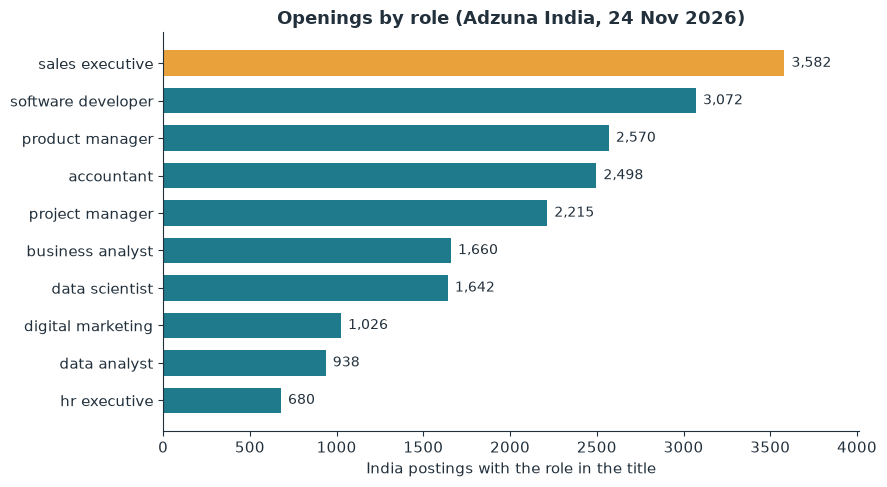

,postings
role,
sales executive,3582
software developer,3072
product manager,2570
accountant,2498
project manager,2215
business analyst,1660
data scientist,1642
digital marketing,1026
data analyst,938


In [2]:
t = totals.postings.sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
colors = [AMBER if v == t.max() else TEAL for v in t.values]
ax.barh(t.index, t.values, color=colors, height=0.68)
for y, v in enumerate(t.values):
    ax.text(v + 40, y, f"{v:,}", va="center", fontsize=10)
ax.set_xlim(0, t.max() * 1.12)
ax.set_xlabel("India postings with the role in the title")
ax.set_title("Openings by role (Adzuna India, 24 Nov 2026)")
plt.tight_layout(); plt.savefig(IMG / "openings_by_role.png", dpi=150, bbox_inches="tight"); plt.show()
totals.postings.sort_values(ascending=False).to_frame("postings")

Sales executive (3,582), software developer (3,072) and product manager (2,570) have the most postings. HR executive (680) and data analyst (938) have the fewest.

These are postings with the role **in the title**, on **one job site**. A bigger number does not mean the role is easier to get. It only means more adverts use that title.

## 2. What each role asks for

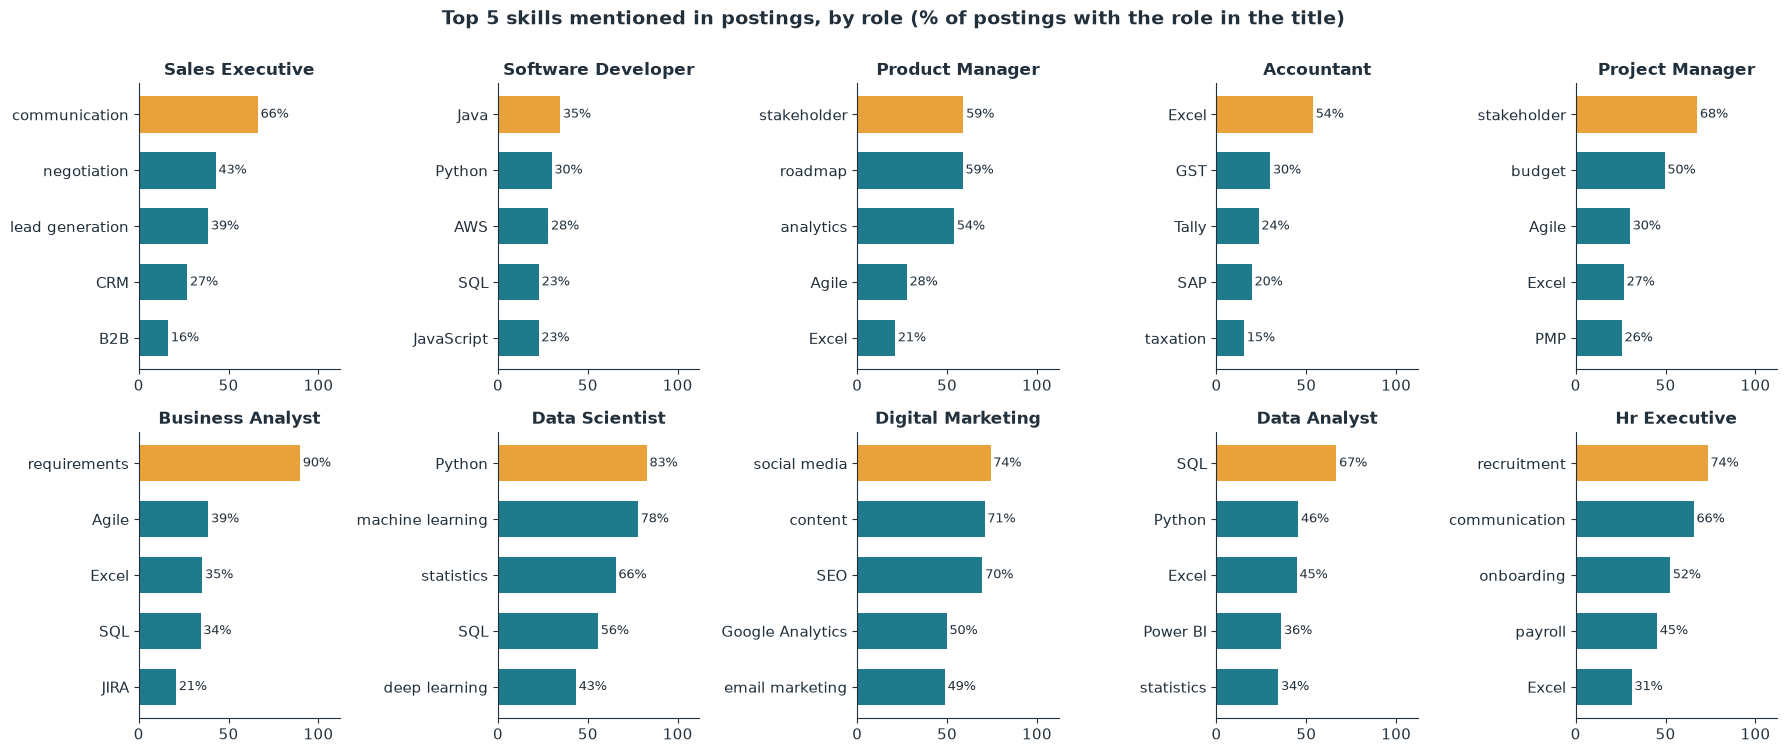

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7.5))
for ax, role in zip(axes.flat, roles):
    top = skills[skills.role == role].sort_values("share_pct", ascending=False).head(5).iloc[::-1]
    ax.barh(top.term, top.share_pct, color=[AMBER if i == len(top) - 1 else TEAL for i in range(len(top))], height=0.65)
    for y, v in enumerate(top.share_pct):
        ax.text(v + 1.5, y, f"{v:.0f}%", va="center", fontsize=9)
    ax.set_xlim(0, 112); ax.set_xticks([0, 50, 100])
    ax.set_title(role.title(), fontsize=12)
fig.suptitle("Top 5 skills mentioned in postings, by role (% of postings with the role in the title)", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig(IMG / "skills_by_role.png", dpi=150, bbox_inches="tight"); plt.show()

Each role has its own short list. The top skill is highlighted.

- **Data analyst:** SQL (67%), Python (46%), Excel (45%).
- **Data scientist:** Python (83%) and machine learning (78%).
- **Software developer:** Java (35%) and Python (30%). No skill is above 35%, which fits with developers using many different languages.
- **Business analyst:** "requirements" (90%), a word from "requirements gathering" rather than a tool.
- **Digital marketing:** social media (74%), content (71%) and SEO (70%).
- **Sales executive and HR executive:** communication is in the top two for both (66%).

Note: I picked a short list of skills to check for each role (8 to 16 skills), so these are the top 5 *of the skills I checked*. A skill I did not check cannot appear here.

## 3. Skills shared across roles

Skills that appear in at least 3 roles (number of roles):
term
Excel       8
SQL         6
Python      4
Agile       3
AWS         3
Power BI    3
JIRA        3


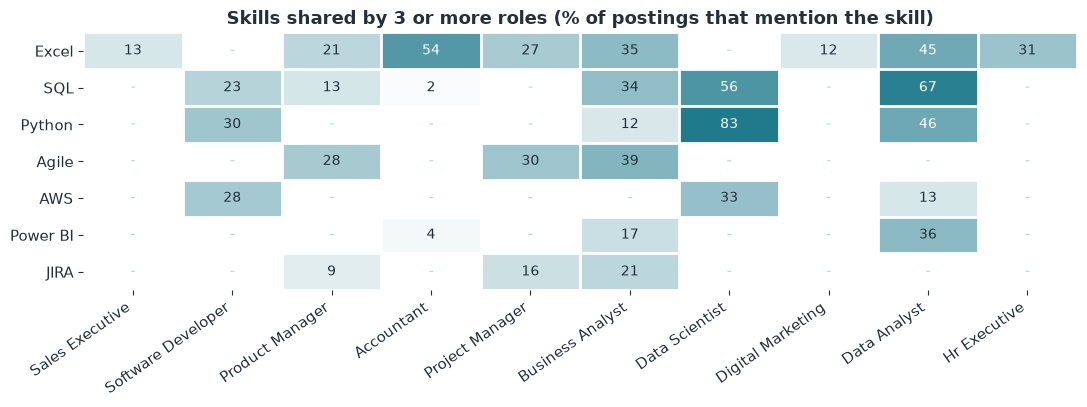

In [4]:
roles_per_skill = skills.groupby("term").role.nunique()
shared = roles_per_skill[roles_per_skill >= 3].sort_values(ascending=False)
heat = skills[skills.term.isin(shared.index)].pivot(index="term", columns="role", values="share_pct")
heat = heat.reindex(index=shared.index, columns=roles)
print("Skills that appear in at least 3 roles (number of roles):")
print(shared.to_string())

cmap = LinearSegmentedColormap.from_list("teal", ["#FFFFFF", TEAL])
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(heat.values, cmap=cmap, vmin=0, vmax=70, aspect="auto")
ax.set_xticks(range(len(roles))); ax.set_xticklabels([r.title() for r in roles], rotation=35, ha="right")
ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        if np.isnan(v):
            ax.text(j, i, "-", ha="center", va="center", color=LIGHT_TEAL)
        else:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 40 else INK, fontsize=10)
for s in ax.spines.values(): s.set_visible(False)
ax.set_xticks(np.arange(-.5, len(roles)), minor=True); ax.set_yticks(np.arange(-.5, len(heat)), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
ax.set_title("Skills shared by 3 or more roles (% of postings that mention the skill)")
plt.tight_layout(); plt.savefig(IMG / "shared_skills_heatmap.png", dpi=150, bbox_inches="tight"); plt.show()

A dash means I did not check that skill for that role. It does not mean the skill is absent.

What I see in the numbers:

- **Excel is in the lists of 8 of the 10 roles.** The two exceptions are data scientist and software developer. It is highest for accountants (54%).
- **SQL is not only for analysts.** It is in 6 roles. It is 67% for data analysts, 56% for data scientists and 34% for business analysts. But it also shows up in 23% of software developer postings and 13% of product manager postings, which is about 1 in 8.
- **Python is in 4 roles:** data scientist (83%), data analyst (46%), software developer (30%) and business analyst (12%).
- Only 7 skills pass the "3 roles" bar (Excel, SQL, Python, Power BI, Agile, JIRA and AWS). Most skills belong to one or two roles. That is why a skill gap check needs a target role.

## 4. Remote and work from home, by role

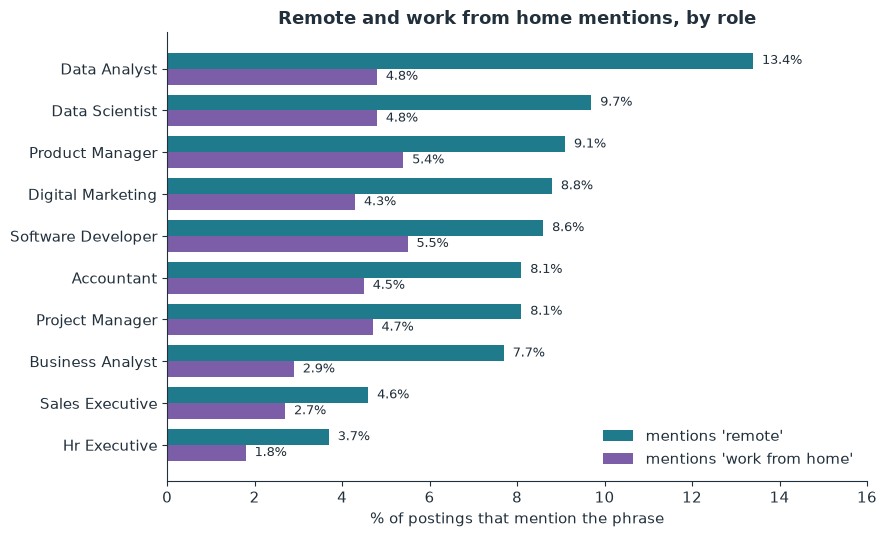

term,hybrid,remote,work from home
role,,,
data analyst,13.5,13.4,4.8
data scientist,15.0,9.7,4.8
product manager,8.8,9.1,5.4
digital marketing,2.9,8.8,4.3
software developer,10.4,8.6,5.5
project manager,11.3,8.1,4.7
accountant,8.1,8.1,4.5
business analyst,10.8,7.7,2.9
sales executive,1.3,4.6,2.7


In [5]:
wa = arrangement.pivot(index="role", columns="term", values="share_pct")
wa = wa.sort_values("remote")
y = np.arange(len(wa)); h = 0.38
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(y + h / 2, wa["remote"], h, color=TEAL, label="mentions 'remote'")
ax.barh(y - h / 2, wa["work from home"], h, color=PLUM, label="mentions 'work from home'")
for i, (r, w) in enumerate(zip(wa["remote"], wa["work from home"])):
    ax.text(r + 0.2, i + h / 2, f"{r:.1f}%", va="center", fontsize=9)
    ax.text(w + 0.2, i - h / 2, f"{w:.1f}%", va="center", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels([r.title() for r in wa.index])
ax.set_xlim(0, 16); ax.set_xlabel("% of postings that mention the phrase")
ax.set_title("Remote and work from home mentions, by role")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(IMG / "remote_by_role.png", dpi=150, bbox_inches="tight"); plt.show()
wa.sort_values("remote", ascending=False)

These are **keyword mentions**. A posting can mention both "remote" and "work from home", so the two shares overlap and I cannot add them up. A mention also does not mean the job is fully remote. It could say "remote-friendly" or "remote onboarding".

Data analyst has the highest share of "remote" mentions (13.4%). HR executive has the lowest on both phrases (3.7% and 1.8%). For most roles the share is under 10%. "Work from home" is in 2% to 6% of postings for every role.

## 5. Skill gap check

This is the main part of the project. The function `skill_gap(role, have_skills, top_n=8)` does this:

1. Take the role's top `top_n` skills, ranked by demand share.
2. Mark each one as "have" or "missing" for the candidate.
3. Work out the **coverage score**:

   **coverage = (sum of the demand shares of the skills the candidate has) / (sum of the demand shares of all top N skills) x 100**

   So a skill that 80% of postings mention counts for more than one that 5% mention. If the candidate has all of the top skills, coverage is 100%. If they have none, it is 0%.
4. List the missing skills, most in demand first.

The same logic is in `analysis/skill_gap.py`, which can be run from the command line.

In [6]:
def skill_gap(role, have_skills, top_n=8):
    have = {s.strip().lower() for s in have_skills}
    d = skills[skills.role == role].sort_values(["share_pct", "term"], ascending=[False, True]).head(top_n)
    table = d[["term", "postings", "share_pct"]].rename(columns={"term": "skill"}).reset_index(drop=True)
    table["have"] = table.skill.str.lower().isin(have).map({True: "Yes", False: "No"})
    coverage = 100 * table.loc[table.have == "Yes", "share_pct"].sum() / table.share_pct.sum()
    missing = table[table.have == "No"].sort_values("share_pct", ascending=False).skill.tolist()
    return {"role": role, "table": table, "coverage_pct": round(coverage, 1), "missing": missing}

rows = []
for role in roles:
    r = skill_gap(role, have_skills)
    rows.append({"role": role, "coverage_pct": r["coverage_pct"], "top 3 missing": ", ".join(r["missing"][:3])})
ranked = pd.DataFrame(rows).sort_values("coverage_pct", ascending=False).reset_index(drop=True)
ranked.index += 1
ranked

,role,coverage_pct,top 3 missing
1,data analyst,77.8,"Tableau, ETL, machine learning"
2,data scientist,49.6,"machine learning, deep learning, AWS"
3,accountant,37.8,"GST, Tally, SAP"
4,business analyst,37.8,"requirements, Agile, JIRA"
5,software developer,28.5,"Java, AWS, JavaScript"
6,product manager,13.9,"stakeholder, roadmap, analytics"
7,project manager,10.6,"stakeholder, budget, Agile"
8,hr executive,10.1,"recruitment, communication, onboarding"
9,sales executive,5.7,"communication, negotiation, lead generation"
10,digital marketing,3.2,"social media, content, SEO"


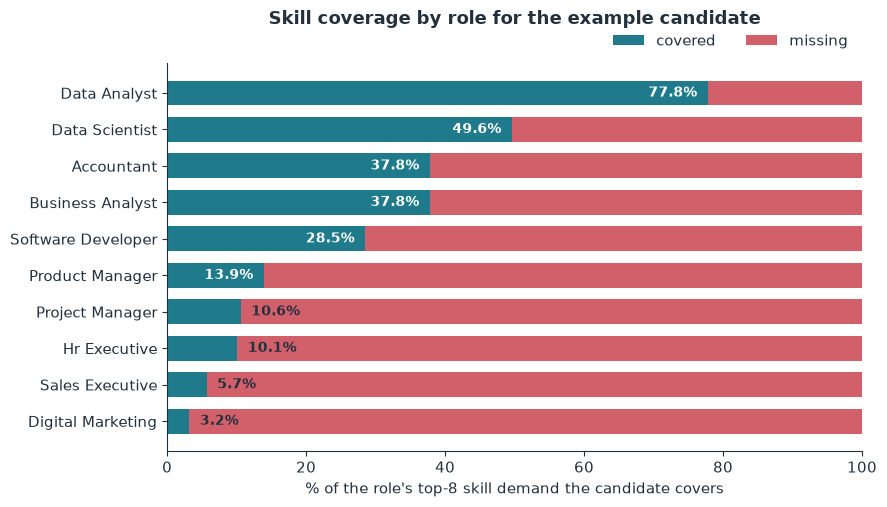

In [7]:
rk = ranked.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(rk.role.str.title(), rk.coverage_pct, color=TEAL, height=0.68, label="covered")
ax.barh(rk.role.str.title(), 100 - rk.coverage_pct, left=rk.coverage_pct, color=ROSE, height=0.68, label="missing")
for y, v in enumerate(rk.coverage_pct):
    ax.text(v - 1.5 if v > 12 else v + 1.5, y, f"{v:.1f}%", va="center", ha="right" if v > 12 else "left",
            color="white" if v > 12 else INK, fontsize=10, fontweight="bold")
ax.set_xlim(0, 100); ax.set_xlabel("% of the role's top-8 skill demand the candidate covers")
ax.set_title("Skill coverage by role for the example candidate", pad=28)
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1.0), ncol=2)
plt.tight_layout(); plt.savefig(IMG / "skill_gap_by_role.png", dpi=150, bbox_inches="tight"); plt.show()

The example candidate knows SQL, Excel, Power BI, Python and statistics. **Data analyst is the best fit (77.8%)**, then data scientist (49.6%). Accountant and business analyst come next, both at 37.8%. For roles like digital marketing (3.2%) and sales executive (5.7%), the candidate covers almost nothing.

The next two tables show the details for two roles.

In [8]:
g = skill_gap("data scientist", have_skills)
print(f"Data scientist: coverage {g['coverage_pct']}%")
print("Missing, most in demand first:", ", ".join(g["missing"]))
g["table"]

Data scientist: coverage 49.6%
Missing, most in demand first: machine learning, deep learning, AWS, NLP, TensorFlow


,skill,postings,share_pct,have
0,Python,1360,82.8,Yes
1,machine learning,1279,77.9,No
2,statistics,1076,65.5,Yes
3,SQL,914,55.7,Yes
4,deep learning,713,43.4,No
5,AWS,537,32.7,No
6,NLP,452,27.5,No
7,TensorFlow,424,25.8,No


For data scientist the candidate already has Python, statistics and SQL, three of the top four skills. The biggest gaps are **machine learning (78%)** and **deep learning (43%)**, then AWS, NLP and TensorFlow.

In [9]:
g = skill_gap("business analyst", have_skills)
print(f"Business analyst: coverage {g['coverage_pct']}%")
print("Missing, most in demand first:", ", ".join(g["missing"]))
g["table"]

Business analyst: coverage 37.8%
Missing, most in demand first: requirements, Agile, JIRA, Tableau


,skill,postings,share_pct,have
0,requirements,1490,89.8,No
1,Agile,643,38.7,No
2,Excel,587,35.4,Yes
3,SQL,571,34.4,Yes
4,JIRA,346,20.8,No
5,Power BI,280,16.9,Yes
6,Tableau,229,13.8,No
7,Python,206,12.4,Yes


For business analyst the candidate covers Excel, SQL, Power BI and Python. The missing items are **"requirements" (90%)**, **Agile (39%)** and **JIRA (21%)**, then Tableau. "Requirements" is a word that comes from requirements gathering, a working method more than a tool. It is the biggest single gap, but it is a different kind of skill from the others.

**What the numbers mean.** They show how often a skill is *mentioned* in postings for the role, and how much of that the candidate already has.

**What they do not mean.**
- A mention is not a requirement. A posting may list a skill as "nice to have".
- Coverage is a **rough guide**. It does not measure how well the candidate knows a skill.
- It only counts the top 8 skills I checked per role (data analyst has 16 skills on my list, data scientist and software developer 9, and the extras are left out). Other skills (and soft skills, degrees, years of experience) are not in it.
- A low score does not mean "do not apply". It shows how much would be new to this candidate.

## 6. Pay (rough)

In [10]:
pay = (totals.avg_advertised_salary_inr / 100000).round(1).sort_values(ascending=False).to_frame("avg advertised salary (lakh a year)")
pay

,avg advertised salary (lakh a year)
role,
data scientist,17.0
product manager,16.4
accountant,13.8
hr executive,13.7
software developer,12.4
project manager,10.6
business analyst,10.3
data analyst,10.1
sales executive,8.6


This is Adzuna's average advertised yearly salary for postings with the role in the title, in lakh rupees (1 lakh = 100,000). **It includes Adzuna's estimates**, not only salaries employers stated, and it is an average, so a few very high or low adverts can move it. I only show it for a rough feel and I do not draw strong conclusions from it.

With that in mind: data scientist (17.0) and product manager (16.4) are at the top of the list, and digital marketing (7.5) and sales executive (8.6) are at the bottom.

## 7. What I would learn first

From the gap tables above, for the example candidate (SQL, Excel, Power BI, Python, statistics). The order inside each line is by demand.

- **Data analyst:** Tableau, ETL, then machine learning. The candidate is already close (77.8%).
- **Data scientist:** machine learning, deep learning, then AWS.
- **Business analyst:** requirements gathering, Agile, then JIRA.
- **Software developer:** Java, AWS, then JavaScript.
- **Accountant:** GST, Tally, then SAP.
- **Product manager:** working with stakeholders, roadmaps, and product analytics.

For roles with a low score (digital marketing, sales executive, HR executive, project manager) almost everything on the list would be new. Those are bigger changes in direction, not small gaps.

## Limits

- **One site, one day.** This is Adzuna on 24 November 2026. Other sites like LinkedIn or Naukri may look different.
- **Mentions, not requirements.** The text of a posting may mention a skill as a bonus or as part of a long list.
- **Title-only role matching.** I count postings with the role in the title. For example "hr executive" misses other HR titles such as "HR generalist" or "talent acquisition".
- **A fixed list of skills per role** that I chose (8 to 16 skills). Skills outside the list are not counted.
- **India only.** Adzuna does not cover Saudi Arabia or the UAE. I tested both and the API returns "not found".
- **Salary is rough.** It includes Adzuna's estimates.